# Анализ сделок купли-продажи

## 1. Библиотеки и настройки

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter, NullLocator, PercentFormatter
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from IPython.display import display

SOURCE = Path("traders_sells")
OUTPUT = Path("traders_sells_outputs")
OUTPUT.mkdir(exist_ok=True)

FIRST_MONTH = "2020-01"
LAST_MONTH = "2020-05"
FIRST_TEST_MONTH = "2020-03"
MIN_GROUP_DEALS = 50
MIN_MONTHLY_DEALS = 30
ALPHA = 0.05

BLUE = "#17658F"
TEAL = "#008074"
ORANGE = "#A75116"
GRAY = "#64748B"
INK = "#182638"
GRID = "#DFE6EC"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "grid.color": GRID,
    "axes.axisbelow": True,
    "figure.dpi": 105,
})

def number(value, digits=0):
    return f"{value:,.{digits}f}".replace(",", " ").replace(".", ",")

def show_figure(fig, filename):
    fig.savefig(
        OUTPUT / f"{filename}.png",
        dpi=175,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()
    plt.close(fig)

## 2. Загрузка и проверка данных

Одна строка — завершённая сделка. Товар определяет `name_id`, месяц — дата продажи. Цены указаны в единицах выгрузки.

In [2]:
columns = [
    "trader_sold", "name_id", "sold_time",
    "bought_time", "bought_price", "sold_price",
]
files = sorted(SOURCE.glob("*.csv"))
if not files:
    raise FileNotFoundError(f"CSV не найдены в {SOURCE.resolve()}")

raw = pd.concat(
    [pd.read_csv(path, usecols=columns) for path in files],
    ignore_index=True,
)

sales = raw.drop_duplicates(subset=columns).copy()
sales["sold_time"] = pd.to_datetime(sales["sold_time"])
sales["bought_time"] = pd.to_datetime(sales["bought_time"])

prices = sales[["bought_price", "sold_price"]]
valid_prices = np.isfinite(prices) & prices.gt(0)
chronological = sales["sold_time"].ge(sales["bought_time"])

assert sales[columns].notna().all().all(), "Есть пропуски в полях сделок"
assert valid_prices.all().all(), "Есть некорректные цены"
assert chronological.all(), "Продажа раньше покупки"

quality = pd.Series({
    "Файлы": len(files),
    "Исходные строки": len(raw),
    "Полные дубли": len(raw) - len(sales),
    "Сделки после очистки": len(sales),
})
display(quality.to_frame("Количество"))

,Количество
Файлы,452
Исходные строки,840356
Полные дубли,7
Сделки после очистки,840349


**Вывод.** Удалили 7 полных дублей. Осталось 840 349 сделок.

## 3. Сделки по месяцам

In [3]:
sales["sold_date"] = sales["sold_time"].dt.normalize()
sales["month"] = sales["sold_time"].dt.to_period("M").astype(str)
monthly = sales.groupby("month").agg(
    deals=("name_id", "size"),
    active_days=("sold_date", "nunique"),
    items=("name_id", "nunique"),
)
monthly["per_day"] = monthly["deals"] / monthly["active_days"]
monthly["change_pct"] = monthly["deals"].pct_change().mul(100)
display(monthly.rename(columns={
    "deals": "Сделки", "active_days": "Дни с продажами", "items": "Товары",
    "per_day": "Сделок за активный день", "change_pct": "К прошлому месяцу, %",
}).round(1))

,Сделки,Дни с продажами,Товары,Сделок за активный день,"К прошлому месяцу, %"
month,,,,,
2020-01,108053,31,4624,3485.6,NaN
2020-02,98346,29,4592,3391.2,-9.0
2020-03,110835,31,4756,3575.3,12.7
2020-04,144502,30,5293,4816.7,30.4
2020-05,110188,31,5178,3554.5,-23.7
2020-06,71585,30,4681,2386.2,-35.0
2020-07,62832,31,4674,2026.8,-12.2
2020-08,51628,31,4159,1665.4,-17.8
2020-09,48407,30,3778,1613.6,-6.2


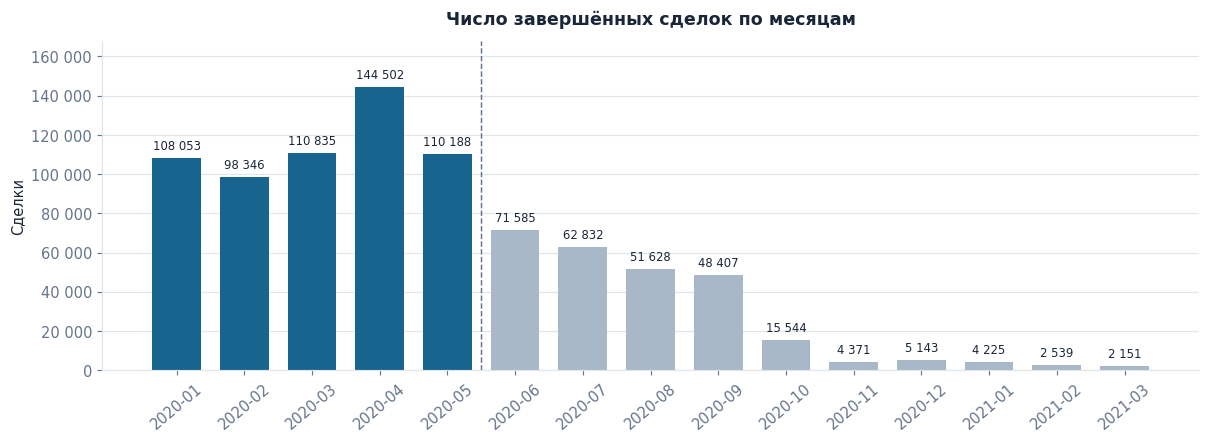

In [4]:
selected_months = monthly.index.to_series().between(FIRST_MONTH, LAST_MONTH)
active_months = monthly.index[selected_months]
month_colors = [BLUE if month in active_months else "#A8B8C9" for month in monthly.index]

fig, ax = plt.subplots(figsize=(11.4, 4.1), layout="constrained")
positions = np.arange(len(monthly))
bars = ax.bar(positions, monthly["deals"], width=0.72, color=month_colors)
ax.bar_label(bars, labels=[number(n) for n in monthly["deals"]], padding=4, fontsize=8)
ax.axvline(len(active_months) - 0.5, color=GRAY, linestyle="--", linewidth=1)
ax.set(xticks=positions, xticklabels=monthly.index, ylabel="Сделки",
       title="Число завершённых сделок по месяцам",
       ylim=(0, monthly["deals"].max() * 1.16))
ax.tick_params(axis="x", labelrotation=40)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: number(x)))
ax.grid(axis="y")
show_figure(fig, "01_monthly_deals")

**Вывод.** Берём январь–май 2020 года. В мае было 110 188 сделок, в июне — 71 585 (−35%).

## 4. Порог числа сделок

In [5]:
active = sales.loc[sales["month"].isin(active_months)].copy()
active["profit"] = active["sold_price"] - active["bought_price"]

holding_time = active["sold_time"] - active["bought_time"]
active["holding_days"] = holding_time.dt.total_seconds() / 86_400
active["is_loss"] = active["profit"].lt(0)

formation = active.loc[active["month"].lt(FIRST_TEST_MONTH)]
all_items = formation.groupby("name_id")["sold_price"].agg(
    deals="size",
    median_price="median",
)
all_items = all_items.sort_values(["median_price", "name_id"])

print(f"Сделок за январь–май: {number(len(active))}.")

Сделок за январь–май: 571 924.


In [6]:
thresholds = [1, 10, 20, 30, MIN_GROUP_DEALS, 100]
coverage_rows = []

for threshold in thresholds:
    kept = all_items.loc[all_items["deals"].ge(threshold)]
    boundaries = kept["median_price"].quantile([1/3, 2/3])
    coverage_rows.append({
        "Минимум сделок": threshold,
        "Товары": len(kept),
        "Сделки": kept["deals"].sum(),
        "Доля сделок, %": 100 * kept["deals"].sum() / len(formation),
        "Нижний тертиль": boundaries.iloc[0],
        "Верхний тертиль": boundaries.iloc[1],
    })

coverage = pd.DataFrame(coverage_rows).set_index("Минимум сделок")
display(coverage.round(2))

,Товары,Сделки,"Доля сделок, %",Нижний тертиль,Верхний тертиль
Минимум сделок,,,,,
1,5428,206399,100.00,4.55,63.99
10,2342,196478,95.19,5.28,40.86
20,1666,187009,90.61,5.50,34.44
30,1325,178819,86.64,5.59,29.16
50,952,164509,79.70,5.90,25.00
100,555,136517,66.14,5.99,20.24


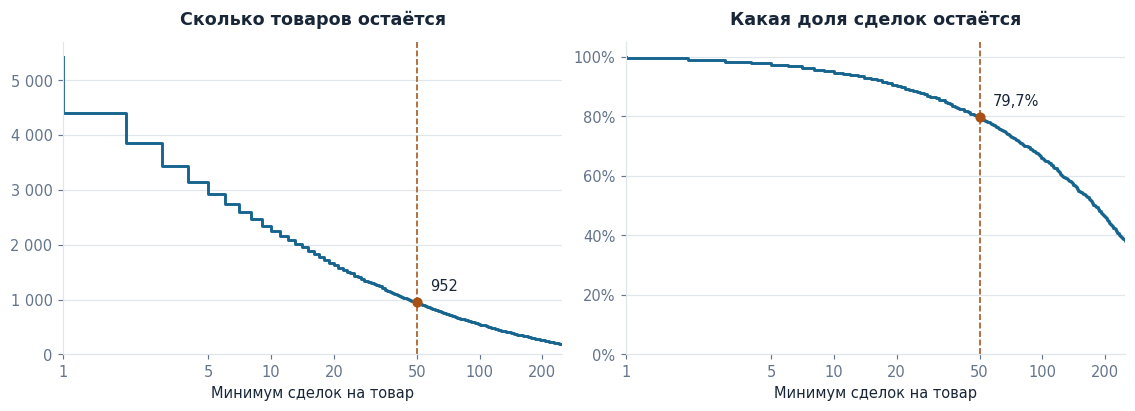

In [7]:
activity = all_items["deals"].value_counts().sort_index(ascending=False)
remaining = activity.cumsum().sort_index()
covered = (activity * activity.index).cumsum().sort_index() / len(formation)

fig, axes = plt.subplots(1, 2, figsize=(10.7, 3.8), layout="constrained", sharex=True)
panels = [
    (axes[0], remaining, "Сколько товаров остаётся"),
    (axes[1], covered * 100, "Какая доля сделок остаётся"),
]
ticks = [1, 5, 10, 20, 50, 100, 200]

for ax, curve, title in panels:
    ax.step(curve.index, curve, where="pre", color=BLUE, linewidth=2)
    ax.axvline(MIN_GROUP_DEALS, color=ORANGE, linestyle="--", linewidth=1.1)
    value = curve.loc[MIN_GROUP_DEALS]
    ax.scatter(MIN_GROUP_DEALS, value, color=ORANGE, zorder=3)
    label = number(value) if ax is axes[0] else f"{number(value, 1)}%"
    ax.annotate(label, (MIN_GROUP_DEALS, value), xytext=(9, 8),
                textcoords="offset points", color=INK)
    ax.set(xscale="log", xlim=(1, 250), xlabel="Минимум сделок на товар",
           title=title, ylim=(0, None))
    ax.set_xticks(ticks, labels=[str(tick) for tick in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(axis="y")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: number(x)))
axes[1].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
show_figure(fig, "06_trade_coverage")

**Вывод.** При пороге 50 сделок за январь–февраль остаются 952 товара и 79,7% сделок.

## 5. Ценовые группы

Группы определяем по медианам января–февраля. Округляем два тертиля, чтобы получить простые границы.

In [8]:
items = all_items.loc[all_items["deals"].ge(MIN_GROUP_DEALS)].copy()
tertiles = items["median_price"].quantile([1/3, 2/3])
lower_cutoff, upper_cutoff = tertiles.round().astype(int)
groups = [f"До {lower_cutoff}", f"От {lower_cutoff} до {upper_cutoff}", f"От {upper_cutoff}"]
group_colors = [BLUE, TEAL, ORANGE]
items["group"] = pd.cut(
    items["median_price"],
    bins=[0, lower_cutoff, upper_cutoff, np.inf],
    right=False,
    labels=groups,
)
print(f"Тертили: {number(tertiles.iloc[0], 2)} и {number(tertiles.iloc[1], 2)}.")

group_summary = items.groupby("group", observed=True).agg(
    Товары=("deals", "size"),
    Сделки=("deals", "sum"),
    Минимальная_медиана=("median_price", "min"),
    Максимальная_медиана=("median_price", "max"),
)
display(group_summary.round(2))

Тертили: 5,90 и 25,00.


,Товары,Сделки,Минимальная_медиана,Максимальная_медиана
group,,,,
До 6,328,53020,2.0,5.99
От 6 до 25,306,62459,6.0,24.99
От 25,318,49030,25.0,1037.49


**Вывод.** Границы 6 и 25 дают три группы примерно по 300 товаров.

## 6. Тепловая карта цен

Строка — ID товара, столбец — интервал цены. Товары отсортированы по медиане, цвет показывает частоту продаж.

In [9]:
eligible_formation = formation.loc[formation["name_id"].isin(items.index)]
log_prices = np.log(eligible_formation["sold_price"])
quartiles = log_prices.groupby(eligible_formation["name_id"]).quantile([0.25, 0.75])
quartiles = quartiles.unstack()

# Границы крайних цен считаем отдельно для каждого товара.
q1 = quartiles[0.25]
q3 = quartiles[0.75]
iqr = q3 - q1
price_fences = pd.DataFrame({
    "lower": q1 - 3 * iqr,
    "upper": q3 + 3 * iqr,
})


def price_outliers(deals):
    log_price = np.log(deals["sold_price"])
    lower = deals["name_id"].map(price_fences["lower"])
    upper = deals["name_id"].map(price_fences["upper"])

    outside_fences = log_price.lt(lower) | log_price.gt(upper)
    return lower.lt(upper) & outside_fences


excluded_on_map = price_outliers(eligible_formation)
heat_sales = eligible_formation.loc[~excluded_on_map]
print(f"Крайних цен убрано с карты: {number(excluded_on_map.sum())}.")

price_edges = np.geomspace(
    heat_sales["sold_price"].min(),
    heat_sales["sold_price"].max(),
    61,
)
item_rows = items.index.get_indexer(heat_sales["name_id"])
row_edges = np.arange(len(items) + 1)

frequency, _, _ = np.histogram2d(
    item_rows,
    heat_sales["sold_price"],
    bins=[row_edges, price_edges],
)
assert frequency.sum() == len(heat_sales), "Часть сделок выпала из тепловой карты"

Крайних цен убрано с карты: 1 960.


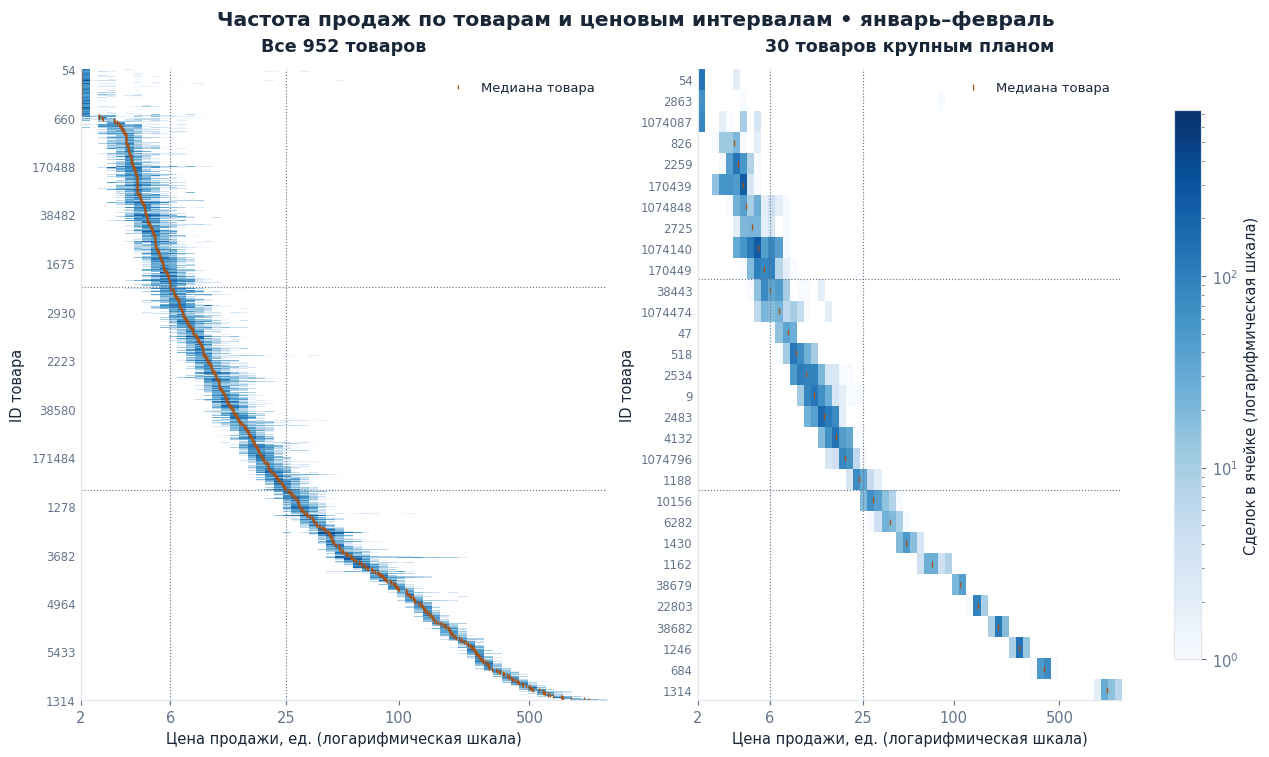

In [10]:
all_rows = np.arange(len(items))
sample_rows = np.linspace(0, len(items) - 1, 30).round().astype(int)
price_ticks = sorted({2, lower_cutoff, upper_cutoff, 100, 500, 2_000, 8_000})
price_ticks = [tick for tick in price_ticks if tick <= price_edges[-1]]

cmap = plt.colormaps["Blues"].copy()
cmap.set_bad("white")
norm = LogNorm(vmin=1, vmax=frequency.max())

figure, axes = plt.subplots(
    1, 2,
    figsize=(12, 7.1),
    layout="constrained",
    gridspec_kw={"width_ratios": [1.24, 1]},
)
panels = [
    (axes[0], all_rows, f"Все {len(items)} товаров"),
    (axes[1], sample_rows, "30 товаров крупным планом"),
]

for axis, rows, title in panels:
    shown_items = items.iloc[rows]
    counts = np.ma.masked_equal(frequency[rows], 0)
    row_centers = np.arange(len(rows)) + 0.5

    grid = axis.pcolormesh(
        price_edges, np.arange(len(rows) + 1), counts,
        cmap=cmap, norm=norm, shading="flat",
    )
    axis.scatter(
        shown_items["median_price"], row_centers,
        s=6 if len(rows) == len(items) else 13,
        marker="|", color=ORANGE, linewidths=0.9, label="Медиана товара",
    )

    row_groups = shown_items["group"].to_numpy()
    group_breaks = np.flatnonzero(row_groups[1:] != row_groups[:-1]) + 1
    for boundary in group_breaks:
        axis.axhline(boundary, color=GRAY, linewidth=0.8, linestyle=":")
    for cutoff in (lower_cutoff, upper_cutoff):
        axis.axvline(cutoff, color=GRAY, linewidth=0.8, linestyle=":")

    if len(rows) > 30:
        labels = np.linspace(0, len(rows) - 1, 14).round().astype(int)
    else:
        labels = np.arange(len(rows))

    axis.set(
        xscale="log",
        ylim=(len(rows), 0),
        yticks=row_centers[labels],
        yticklabels=shown_items.index[labels].astype(str),
        title=title,
        xlabel="Цена продажи, ед. (логарифмическая шкала)",
        ylabel="ID товара",
    )
    axis.set_xticks(price_ticks, labels=[number(tick) for tick in price_ticks])
    axis.xaxis.set_minor_locator(NullLocator())
    axis.tick_params(axis="y", labelsize=8, length=0)
    axis.legend(loc="upper right", frameon=False, fontsize=9)

figure.suptitle(
    "Частота продаж по товарам и ценовым интервалам • январь–февраль",
    fontsize=14,
    fontweight="bold",
)
figure.colorbar(grid, ax=axes, label="Сделок в ячейке (логарифмическая шкала)", shrink=0.87)
show_figure(figure, "02_price_heatmap")

**Вывод.** Цены меняются плавно. Для карты отсеяли 1 960 крайних цен по правилу трёх межквартильных размахов для каждого товара.

## 7. Проверка средних цен

Группы фиксируем по январю–февралю. В марте–мае считаем одну среднюю на товар. Пары сравниваем двусторонним t-тестом Уэлча с поправкой Холма при уровне 0,05.

In [11]:
in_test_period = active["month"].between(FIRST_TEST_MONTH, LAST_MONTH)
segmented = active.loc[in_test_period].join(items[["group"]], on="name_id", how="inner")


def mean_prices_by_item(deals):
    averages = deals.groupby("name_id")["sold_price"].agg(
        test_deals="size",
        mean_price="mean",
    )
    return averages.join(items[["group"]])


def welch_comparisons(data, labels):
    results = []

    for cheaper, dearer in combinations(labels, 2):
        cheaper_prices = data.loc[data["group"].eq(cheaper), "mean_price"].to_numpy()
        dearer_prices = data.loc[data["group"].eq(dearer), "mean_price"].to_numpy()
        test = ttest_ind(dearer_prices, cheaper_prices, equal_var=False)
        interval = test.confidence_interval(confidence_level=0.95)

        results.append({
            "pair": f"«{dearer}» − «{cheaper}»",
            "difference": dearer_prices.mean() - cheaper_prices.mean(),
            "ci_low": interval.low,
            "ci_high": interval.high,
            "t": test.statistic,
            "p": test.pvalue,
        })

    result = pd.DataFrame(results).sort_values("p")

    # Поправка Холма применяется к p-значениям в порядке возрастания.
    multipliers = np.arange(len(result), 0, -1)
    scaled_p = result["p"].to_numpy() * multipliers
    result["p_holm"] = np.minimum(1, np.maximum.accumulate(scaled_p))
    return result.sort_index()

In [12]:
checked = mean_prices_by_item(segmented)

summary = checked.groupby("group", observed=True).agg(
    items=("mean_price", "size"),
    deals=("test_deals", "sum"),
    mean=("mean_price", "mean"),
    sd=("mean_price", "std"),
)
print(f"В проверку вошёл {len(checked)} из {len(items)} товаров.")
display(summary.rename(columns={
    "items": "Товары", "deals": "Сделки", "mean": "Средняя цена",
    "sd": "Стандартное отклонение",
}).round(2))

В проверку вошёл 951 из 952 товаров.


,Товары,Сделки,Средняя цена,Стандартное отклонение
group,,,,
До 6,327,88974,4.25,1.60
От 6 до 25,306,93177,13.83,6.21
От 25,318,74510,183.51,188.79


In [13]:
without_may = segmented.loc[segmented["month"].lt(LAST_MONTH)]
without_outliers = segmented.loc[~price_outliers(segmented)]

tests = welch_comparisons(checked, groups)
tests_without_may = welch_comparisons(mean_prices_by_item(without_may), groups)

checked_trimmed = mean_prices_by_item(without_outliers)
tests_trimmed = welch_comparisons(checked_trimmed, groups)
trimmed_summary = checked_trimmed.groupby("group", observed=True)["mean_price"].agg(
    size="size",
    mean="mean",
)

removed = len(segmented) - len(without_outliers)
print(f"Для дополнительной проверки исключили {number(removed)} крайних цен.")
display(trimmed_summary.rename(columns={
    "size": "Товары после отсечения",
    "mean": "Средняя цена после отсечения",
}).round(2))

Для дополнительной проверки исключили 8 995 крайних цен.


,Товары после отсечения,Средняя цена после отсечения
group,,
До 6,325,4.05
От 6 до 25,306,13.28
От 25,318,181.61


In [14]:
report = tests.copy()
report["p_holm_mar_apr"] = tests_without_may["p_holm"]
report["p_holm_trimmed"] = tests_trimmed["p_holm"]

report = report.rename(columns={
    "pair": "Пара",
    "difference": "Разница",
    "ci_low": "95% ДИ, нижняя",
    "ci_high": "95% ДИ, верхняя",
    "t": "t",
    "p": "p",
    "p_holm": "p Холма",
    "p_holm_mar_apr": "p Холма без мая",
    "p_holm_trimmed": "p Холма без крайних цен",
})

p_columns = ["p", "p Холма", "p Холма без мая", "p Холма без крайних цен"]
decimal_columns = ["Разница", "95% ДИ, нижняя", "95% ДИ, верхняя", "t"]
formats = dict.fromkeys(p_columns, "{:.2e}")
formats.update(dict.fromkeys(decimal_columns, "{:.2f}"))

display(report.style.hide(axis="index").format(formats))

Пара,Разница,"95% ДИ, нижняя","95% ДИ, верхняя",t,p,p Холма,p Холма без мая,p Холма без крайних цен
«От 6 до 25» − «До 6»,9.58,8.86,10.30,26.17,9.38e-84,2.81e-83,1.15e-84,1.83e-87
«От 25» − «До 6»,179.26,158.43,200.09,16.93,2.95e-46,5.89e-46,2.16e-46,7.61e-46
«От 25» − «От 6 до 25»,169.68,148.84,190.52,16.02,9.55e-43,9.55e-43,4.15e-43,9.75e-43


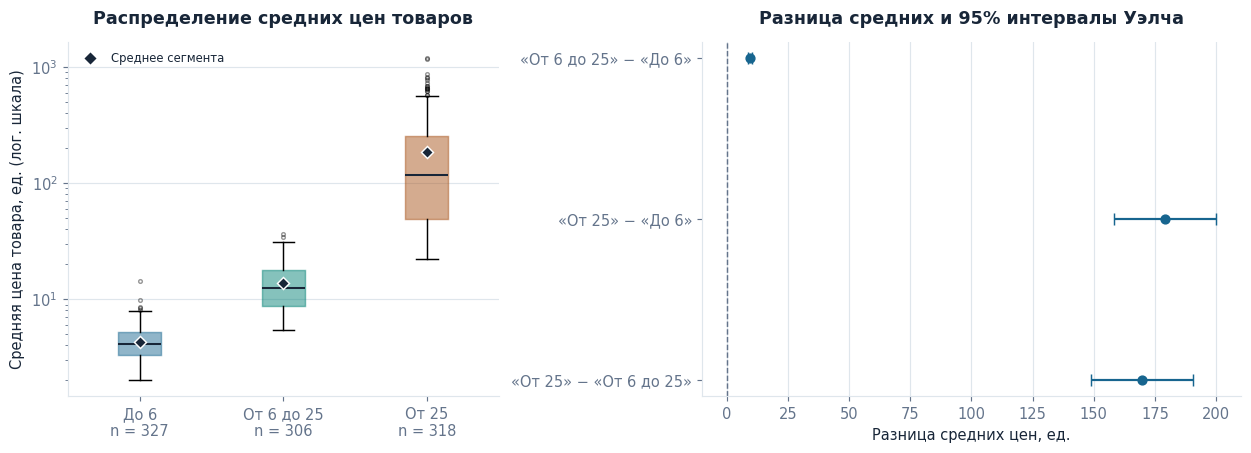

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1.25]})
price_axis, difference_axis = axes

values = [checked.loc[checked["group"].eq(group), "mean_price"] for group in groups]
boxes = price_axis.boxplot(values, patch_artist=True, showmeans=True,
                   meanprops={"marker": "D", "markerfacecolor": INK, "markeredgecolor": "white"},
                   medianprops={"color": INK, "linewidth": 1.4},
                   flierprops={"markersize": 2.5, "alpha": 0.4})
for box, color in zip(boxes["boxes"], group_colors):
    box.set_facecolor(color)
    box.set_edgecolor(color)
    box.set_alpha(0.48)
price_axis.set(yscale="log", title="Распределение средних цен товаров",
       ylabel="Средняя цена товара, ед. (лог. шкала)")
group_labels = [f"{group}\nn = {count}" for group, count in zip(groups, summary["items"])]
price_axis.set_xticks([1, 2, 3], labels=group_labels)
price_axis.grid(axis="y")
price_axis.plot([], [], "D", color=INK, markersize=5, label="Среднее сегмента")
price_axis.legend(frameon=False, loc="upper left", fontsize=8)

difference_axis.axvline(0, linestyle="--", color=GRAY, linewidth=1)
pair_positions = np.arange(len(tests))
errors = np.array([
    tests["difference"] - tests["ci_low"],
    tests["ci_high"] - tests["difference"],
])
difference_axis.errorbar(
    tests["difference"], pair_positions, xerr=errors,
    fmt="o", color=BLUE, capsize=4,
)
difference_axis.set(yticks=np.arange(len(tests)), yticklabels=tests["pair"],
       xlabel="Разница средних цен, ед.", title="Разница средних и 95% интервалы Уэлча")
difference_axis.invert_yaxis()
difference_axis.grid(axis="x")
show_figure(fig, "03_group_comparisons")

**Вывод.** Все три пары различаются. Результат сохраняется без мая и без крайних цен. Тест предполагает независимость товаров.

## 8. Сколько групп выделить

Сравниваем варианты с 2–5 группами по квантилям января–февраля. Поправку Холма применяем отдельно для каждого варианта.

In [16]:
alternatives = []

for group_count in [2, 3, 4, 5]:
    cuts = items["median_price"].quantile(np.arange(1, group_count) / group_count)
    labels = [f"Группа {i}" for i in range(1, group_count + 1)]
    assigned = pd.cut(
        items["median_price"],
        bins=[0, *cuts, np.inf],
        right=False,
        labels=labels,
    )
    alternative = checked.assign(group=assigned.reindex(checked.index))
    sizes = alternative.groupby("group", observed=True).size()
    comparisons = welch_comparisons(alternative, labels)
    significant = comparisons["p_holm"].lt(ALPHA).sum()

    alternatives.append({
        "Группы": group_count,
        "Пороги, ед.": " / ".join(number(cut, 2) for cut in cuts),
        "Товаров в группах": " / ".join(map(str, sizes)),
        "Значимые пары": f"{significant} из {len(comparisons)}",
        "Макс. p Холма": f"{comparisons['p_holm'].max():.2e}",
    })
display(pd.DataFrame(alternatives).set_index("Группы"))

,"Пороги, ед.",Товаров в группах,Значимые пары,Макс. p Холма
Группы,,,,
2,"10,99",473 / 478,1 из 1,3.31e-44
3,"5,90 / 25,00",315 / 318 / 318,3 из 3,7.64e-43
4,"4,72 / 10,99 / 44,76",238 / 235 / 240 / 238,6 из 6,3.31e-41
5,"4,12 / 7,42 / 17,49 / 78,51",190 / 190 / 189 / 191 / 191,10 из 10,8.01e-39


**Вывод.** При 2–5 группах все пары значимы. Для отчёта оставляем три сегмента с понятным разделением на дешевые средние и дорогие


## 9. Рейтинг товаров

Валовой ROI — прибыль по завершённым сделкам, делённая на затраты на покупку. Сравниваем все товары и товары с минимум 30 сделками в каждом месяце января–апреля. Май проверяем отдельно.

In [17]:
def trade_metrics(data, by="name_id"):
    metrics = data.groupby(by).agg(
        deals=("profit", "size"),
        cost=("bought_price", "sum"),
        gross_profit=("profit", "sum"),
        profit_per_deal=("profit", "mean"),
        median_buy=("bought_price", "median"),
        median_sell=("sold_price", "median"),
        median_days=("holding_days", "median"),
        loss_share=("is_loss", "mean"),
    )
    metrics["roi"] = metrics["gross_profit"] / metrics["cost"]
    return metrics


ranking_period = active.loc[active["month"].lt(LAST_MONTH)]
may = active.loc[active["month"].eq(LAST_MONTH)]

counts_by_month = ranking_period.groupby(["name_id", "month"]).size().unstack(fill_value=0)
counts_by_month = counts_by_month.reindex(columns=active_months[:-1], fill_value=0)
min_monthly = counts_by_month.min(axis=1)

training_metrics = trade_metrics(ranking_period)
regular_items = min_monthly.ge(MIN_MONTHLY_DEALS)
eligible = training_metrics.loc[regular_items].sort_values(
    ["roi", "deals"],
    ascending=False,
    kind="stable",
)
may_metrics = trade_metrics(may)

winner = eligible.index[0]
may_results = may_metrics[["roi", "deals"]].add_prefix("may_")
leaders = eligible.head(10).join(may_results)
print(f"Товаров с регулярными продажами: {len(eligible)}. Лидер по ROI: {winner}.")

leaders_by_threshold = []
for threshold in [20, 30, 50]:
    qualifying = min_monthly.ge(threshold)
    leaders_by_threshold.append(int(training_metrics.loc[qualifying, "roi"].idxmax()))
print("Лидер при порогах 20, 30 и 50 сделок в месяц:", leaders_by_threshold)

Товаров с регулярными продажами: 678. Лидер по ROI: 171465.
Лидер при порогах 20, 30 и 50 сделок в месяц: [171465, 171465, 171465]


In [18]:
metrics_ru = {
    "deals": "Сделки", "cost": "Вложения", "gross_profit": "Валовая прибыль",
    "profit_per_deal": "Прибыль на сделку", "median_buy": "Медиана покупки",
    "median_sell": "Медиана продажи", "median_days": "Медиана дней до продажи",
    "loss_share": "Доля убыточных, %", "roi": "ROI, %",
    "may_roi": "ROI в мае, %", "may_deals": "Сделки в мае",
}

def show_metrics(table, fields):
    table = table[fields].copy()
    percentage_columns = table.columns.intersection(["roi", "loss_share", "may_roi"])
    table[percentage_columns] *= 100
    display(table.rename(columns=metrics_ru).round(2))

show_metrics(leaders, ["deals", "cost", "profit_per_deal", "roi", "may_deals", "may_roi"])

,Сделки,Вложения,Прибыль на сделку,"ROI, %",Сделки в мае,"ROI в мае, %"
name_id,,,,,,
171465,438,171.41,1.65,422.52,74,445.58
54,243,123.94,1.93,378.05,9,202.24
7010,185,93.32,1.50,296.49,5,336.68
1072908,216,117.97,1.53,280.88,34,235.10
20269,399,218.76,1.49,271.32,117,294.87
201774,491,269.41,1.47,268.01,61,255.54
201816,221,126.17,1.44,252.45,22,257.43
1073958,402,234.92,1.45,247.92,79,166.22
2261,191,115.65,1.45,239.55,24,256.61


In [19]:
criteria_rows = []
criteria_names = {
    "roi": "Доходность на вложения",
    "profit_per_deal": "Прибыль на сделку",
    "gross_profit": "Суммарная валовая прибыль",
}
rankings = [
    ("Все товары", training_metrics),
    ("Регулярные продажи", eligible),
]
may_deal_counts = may_metrics["deals"]

for scope, table in rankings:
    for metric, criterion in criteria_names.items():
        item_id = table[metric].idxmax()
        row = table.loc[item_id]
        may_count = may_deal_counts.get(item_id, 0)

        criteria_rows.append({
            "Выборка": scope,
            "Критерий": criterion,
            "ID товара": item_id,
            "Сделки в январе–апреле": int(row["deals"]),
            "Валовая прибыль на сделку": number(row["profit_per_deal"], 2),
            "Валовая прибыль всего": number(row["gross_profit"], 2),
            "ROI, %": number(row["roi"] * 100, 2),
            "Сделки в мае": int(may_count),
        })
display(pd.DataFrame(criteria_rows).set_index(["Выборка", "Критерий"]))

ID товара  \
Выборка            Критерий                               
Все товары         Доходность на вложения          3600   
                   Прибыль на сделку               3985   
                   Суммарная валовая прибыль       9220   
Регулярные продажи Доходность на вложения        171465   
                   Прибыль на сделку               3895   
                   Суммарная валовая прибыль       9220   

                                              Сделки в январе–апреле  \
Выборка            Критерий                                            
Все товары         Доходность на вложения                          1   
                   Прибыль на сделку                               1   
                   Суммарная валовая прибыль                     517   
Регулярные продажи Доходность на вложения                        438   
                   Прибыль на сделку                             169   
                   Суммарная валовая прибыль                     517   

                                             Валовая прибыль на сделку  \
Выборка            Критерий                                              
Все товары         Доходность на вложения                         2,60   
                   Прибыль на сделку                          1 706,77   
                   Суммарная валовая прибыль                     57,28   
Регулярные продажи Доходность на вложения                         1,65   
                   Прибыль на сделку                             95,76   
                   Суммарная валовая прибыль                     57,28   

                                             Валовая прибыль всего    ROI, %  \
Выборка            Критерий                                                    
Все товары         Доходность на вложения                     2,60  2 600,00   
                   Прибыль на сделку                      1 706,77     23,41   
                   Суммарная валовая прибыль             29 614,91     12,08   
Регулярные продажи Доходность на вложения                   724,25    422,52   
                   Прибыль на сделку                     16 183,78     16,92   
                   Суммарная валовая прибыль             29 614,91     12,08   

                                              Сделки в мае  
Выборка            Критерий                                 
Все товары         Доходность на вложения                0  
                   Прибыль на сделку                     0  
                   Суммарная валовая прибыль           101  
Регулярные продажи Доходность на вложения               74  
                   Прибыль на сделку                    23  
                   Суммарная валовая прибыль           101

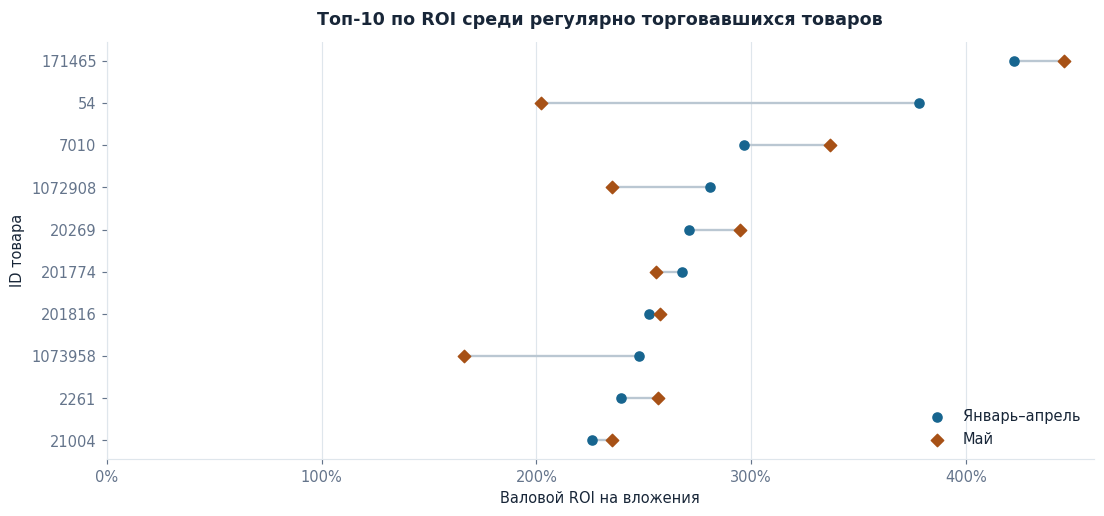

In [20]:
fig, ax = plt.subplots(figsize=(10.4, 4.8), layout="constrained")
y = np.arange(len(leaders))
ax.hlines(y, leaders["roi"] * 100, leaders["may_roi"] * 100, color="#BAC7D2", linewidth=1.6)
ax.scatter(leaders["roi"] * 100, y, s=39, color=BLUE, label="Январь–апрель", zorder=3)
ax.scatter(leaders["may_roi"] * 100, y, s=36, color=ORANGE, marker="D", label="Май", zorder=3)
ax.set(yticks=y, yticklabels=leaders.index.astype(str), xlabel="Валовой ROI на вложения",
       ylabel="ID товара", title="Топ-10 по ROI среди регулярно торговавшихся товаров")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_xlim(left=0)
ax.grid(axis="x")
ax.legend(loc="lower right", frameon=False)
show_figure(fig, "04_roi_leaders")

**Вывод.** Без порога лидирует товар 3600 с одной сделкой. Среди регулярно продававшихся товаров лидирует 171465, по суммарной прибыли — 9220 в обоих рейтингах.

## 10. Товар 171465 по месяцам

In [21]:
winner_deals = active.loc[active["name_id"].eq(winner)]
winner_monthly = trade_metrics(winner_deals, by="month")

show_metrics(
    winner_monthly,
    ["deals", "median_buy", "median_sell", "gross_profit", "roi", "median_days", "loss_share"],
)

winner_periods = pd.DataFrame({
    "Январь–апрель": eligible.loc[winner],
    "Май": may_metrics.loc[winner],
}).T
show_metrics(
    winner_periods,
    [
        "deals", "median_buy", "median_sell", "median_days",
        "cost", "gross_profit", "profit_per_deal", "roi", "loss_share",
    ],
)

,Сделки,Медиана покупки,Медиана продажи,Валовая прибыль,"ROI, %",Медиана дней до продажи,"Доля убыточных, %"
month,,,,,,,
2020-01,66,0.33,2.0,110.22,506.06,7.61,0.0
2020-02,119,0.35,2.0,190.29,398.85,7.89,0.0
2020-03,135,0.33,2.0,226.37,364.52,8.01,0.0
2020-04,118,0.32,2.0,197.37,495.66,10.11,0.0
2020-05,74,0.29,2.0,126.99,445.58,11.36,0.0


,Сделки,Медиана покупки,Медиана продажи,Медиана дней до продажи,Вложения,Валовая прибыль,Прибыль на сделку,"ROI, %","Доля убыточных, %"
Январь–апрель,438.0,0.33,2.0,8.03,171.41,724.25,1.65,422.52,0.0
Май,74.0,0.29,2.0,11.36,28.50,126.99,1.72,445.58,0.0


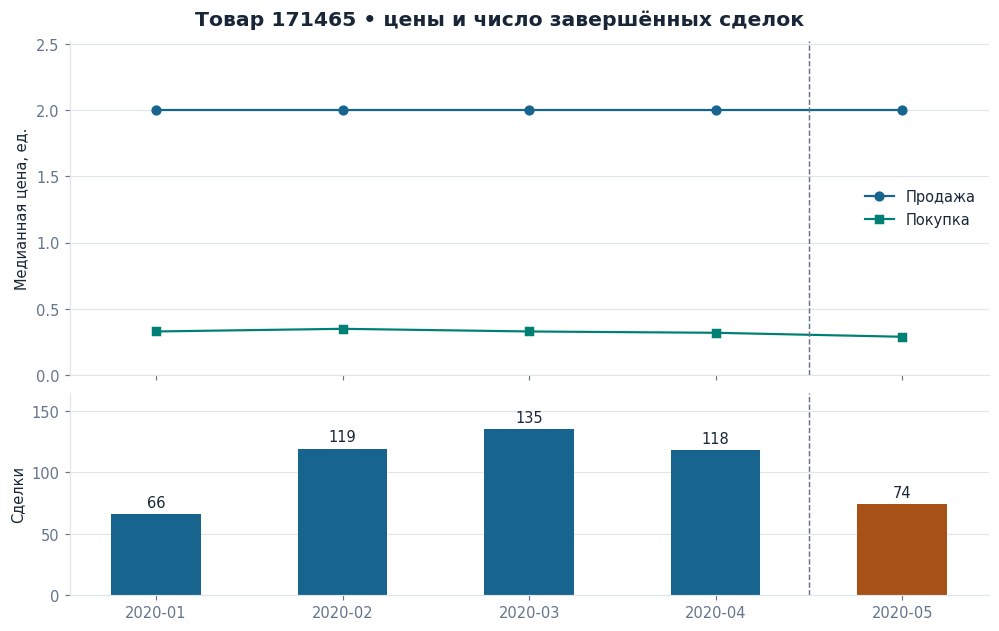

In [22]:
fig, (prices_ax, deals_ax) = plt.subplots(2, 1, figsize=(9.4, 5.9), sharex=True,
                                        layout="constrained", height_ratios=[1.65, 1])
x = np.arange(len(winner_monthly))
prices_ax.plot(x, winner_monthly["median_sell"], color=BLUE, marker="o", label="Продажа")
prices_ax.plot(x, winner_monthly["median_buy"], color=TEAL, marker="s", label="Покупка")
prices_ax.set(ylabel="Медианная цена, ед.", ylim=(0, winner_monthly["median_sell"].max() * 1.26))
prices_ax.legend(frameon=False, loc="center right")
prices_ax.grid(axis="y")

bars = deals_ax.bar(x, winner_monthly["deals"], width=0.48,
                    color=[BLUE] * (len(x) - 1) + [ORANGE])
deals_ax.bar_label(bars, padding=3)
deals_ax.set(ylabel="Сделки", ylim=(0, winner_monthly["deals"].max() * 1.22),
             xticks=x, xticklabels=winner_monthly.index)
deals_ax.grid(axis="y")
for ax in (prices_ax, deals_ax):
    ax.axvline(x[-1] - 0.5, linestyle="--", linewidth=1, color=GRAY)
fig.suptitle(f"Товар {winner} • цены и число завершённых сделок",
             fontsize=14, fontweight="bold")
show_figure(fig, "05_winner_history")

**Вывод.** У товара 171465 валовой ROI составил 422,5% за январь–апрель и 445,6% в мае на 74 сделках.

## 11. Концентрация торговли

Сортируем товары по числу сделок. В этом порядке считаем накопленные доли сделок и оборота.

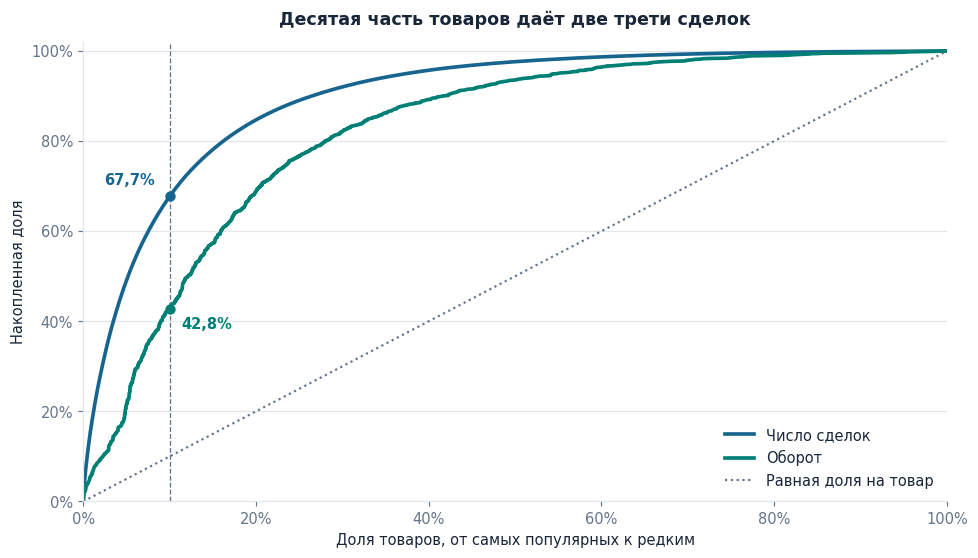

In [23]:
popular = active.groupby("name_id", as_index=False).agg(
    deals=("name_id", "size"),
    turnover=("sold_price", "sum"),
)
popular = popular.sort_values(["deals", "name_id"], ascending=[False, True])

totals_by_item = popular[["deals", "turnover"]]
shares = totals_by_item.cumsum() / totals_by_item.sum()
shares.index = np.arange(1, len(shares) + 1) / len(shares)
shares.loc[0] = 0
shares = shares.sort_index()
top_fraction = 0.10
top_deals = np.interp(top_fraction, shares.index, shares["deals"])
top_turnover = np.interp(top_fraction, shares.index, shares["turnover"])

fig, ax = plt.subplots(figsize=(9.2, 5.2), layout="constrained")
ax.plot(shares.index, shares["deals"], color=BLUE, linewidth=2.5, label="Число сделок")
ax.plot(shares.index, shares["turnover"], color=TEAL, linewidth=2.5, label="Оборот")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle=":", label="Равная доля на товар")
ax.axvline(top_fraction, color=GRAY, linewidth=0.9, linestyle="--")
for value, color in [(top_deals, BLUE), (top_turnover, TEAL)]:
    ax.scatter(top_fraction, value, color=color, s=37, zorder=3)
    ax.annotate(f"{number(value * 100, 1)}%", (top_fraction, value),
                xytext=(-10, 8) if color == BLUE else (8, -14),
                ha="right" if color == BLUE else "left",
                textcoords="offset points", color=color, fontweight="bold")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Доля товаров, от самых популярных к редким",
       ylabel="Накопленная доля", title="Десятая часть товаров даёт две трети сделок")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y")
ax.legend(loc="lower right", frameon=False)
show_figure(fig, "07_sales_concentration")

**Вывод.** Топ-10% товаров по числу сделок дают 67,7% сделок и 42,8% оборота.

## 12. Прибыль и доходность по сегментам

Сравниваем три сегмента на завершённых сделках марта–мая. Оборот — сумма цен продажи.

In [24]:
economics = segmented.groupby("group", observed=True).agg(
    deals=("name_id", "size"), turnover=("sold_price", "sum"),
    profit=("profit", "sum"), cost=("bought_price", "sum"),
).reindex(groups)
totals_by_group = economics[["deals", "turnover", "profit"]]
components = totals_by_group / totals_by_group.sum()
segment_roi = economics["profit"] / economics["cost"]

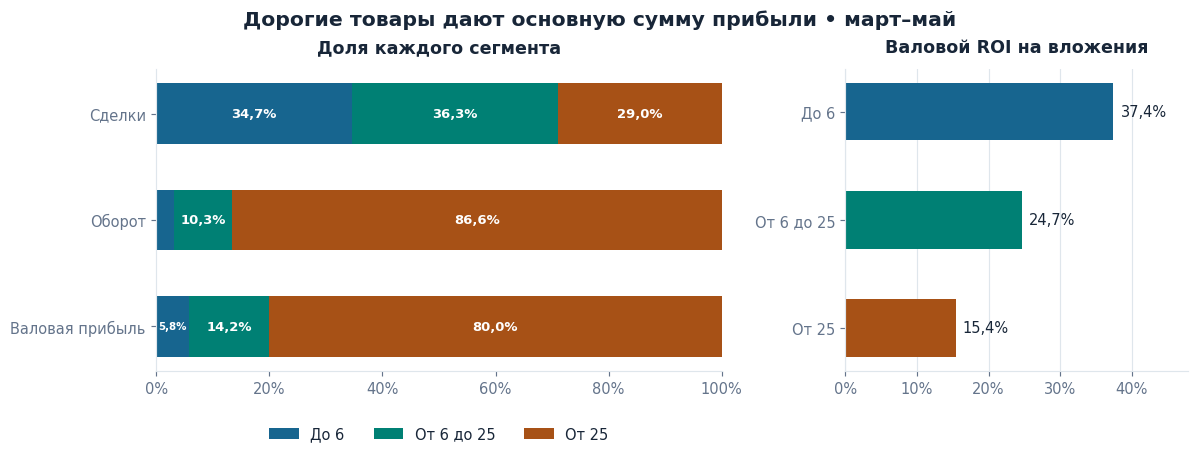

In [25]:
fig, (share_ax, roi_ax) = plt.subplots(1, 2, figsize=(11.3, 4.25), layout="constrained",
                                      gridspec_kw={"width_ratios": [1.65, 1]})
offset = np.zeros(3)
for group, color in zip(groups, group_colors):
    widths = components.loc[group].to_numpy()
    share_ax.barh(range(3), widths, left=offset, color=color, height=0.57, label=group)
    for y, (start, width) in enumerate(zip(offset, widths)):
        if width >= 0.05:
            label_size = 7 if width < 0.075 else 9
            share_ax.text(
                start + width / 2, y, f"{number(width * 100, 1)}%",
                color="white", ha="center", va="center",
                fontsize=label_size, fontweight="bold",
            )
    offset += widths
share_ax.set(yticks=range(3), yticklabels=["Сделки", "Оборот", "Валовая прибыль"],
             xlim=(0, 1), title="Доля каждого сегмента")
share_ax.invert_yaxis()
share_ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
share_ax.legend(loc="lower center", bbox_to_anchor=(.5, -0.28), ncols=3, frameon=False)

bars = roi_ax.barh(groups, segment_roi, color=group_colors, height=0.53)
roi_ax.bar_label(bars, labels=[f"{number(value * 100, 1)}%" for value in segment_roi], padding=5)
roi_ax.set(title="Валовой ROI на вложения", xlim=(0, segment_roi.max() * 1.28))
roi_ax.invert_yaxis()
roi_ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
roi_ax.grid(axis="x")
fig.suptitle("Дорогие товары дают основную сумму прибыли • март–май",
             fontsize=14, fontweight="bold")
show_figure(fig, "08_segment_economics")

**Вывод.** Дорогой сегмент дал 80% валовой прибыли. У дешёвого выше ROI — 37,4% против 15,4%.

## 13. Срок перепродажи и доля убытков

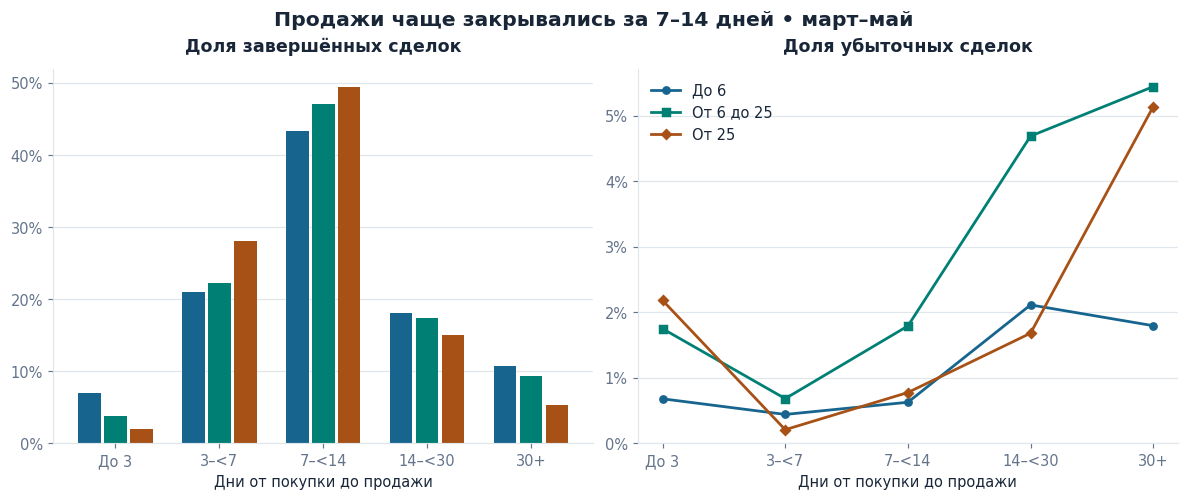

In [26]:
hold_labels = ["До 3", "3–<7", "7–<14", "14–<30", "30+"]
hold_bucket = pd.cut(
    segmented["holding_days"],
    bins=[0, 3, 7, 14, 30, np.inf],
    right=False,
    labels=hold_labels,
)
by_holding = segmented.groupby(["group", hold_bucket], observed=True).agg(
    deals=("name_id", "size"),
    loss_share=("is_loss", "mean"),
)
holding_counts = by_holding["deals"].unstack().reindex(index=groups, columns=hold_labels)
holding_shares = holding_counts.div(holding_counts.sum(axis=1), axis=0)
holding_losses = by_holding["loss_share"].unstack().reindex(index=groups, columns=hold_labels)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.65), layout="constrained")
x = np.arange(len(hold_labels))
for i, (group, color, marker) in enumerate(zip(groups, group_colors, ["o", "s", "D"])):
    axes[0].bar(x + (i - 1) * .25, holding_shares.loc[group], width=.22, color=color)
    axes[1].plot(x, holding_losses.loc[group], color=color, marker=marker, linewidth=1.9,
                 label=group, markersize=5)
for ax, title in zip(axes, ["Доля завершённых сделок", "Доля убыточных сделок"]):
    ax.set(xticks=x, xticklabels=hold_labels, xlabel="Дни от покупки до продажи",
           title=title, ylim=(0, None))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y")
axes[1].legend(frameon=False, loc="upper left")
fig.suptitle("Продажи чаще закрывались за 7–14 дней • март–май",
             fontsize=14, fontweight="bold")
show_figure(fig, "09_holding_and_losses")

**Вывод.** Чаще всего сделки закрывались за 7–14 дней. У дорогих товаров доля убытков — 0,2% при продаже за 3–7 дней и 5,1% через 30 дней и позже.

## 14. Цены покупки и продажи

Цвет ячейки показывает число сделок. Диагональ соответствует равным ценам покупки и продажи.

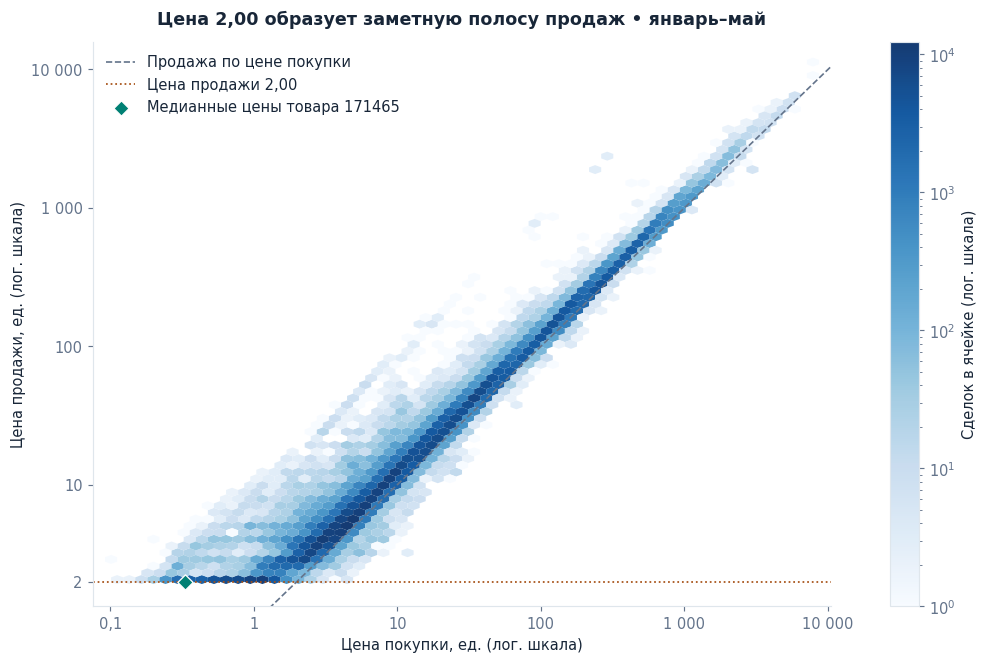

In [27]:
price_floor = sales["sold_price"].min()
at_floor = active["sold_price"].eq(price_floor)
logged_buy = np.log10(active["bought_price"])
logged_sell = np.log10(active["sold_price"])
low_x, high_x = logged_buy.min() - .12, logged_buy.max() + .12
low_y, high_y = logged_sell.min() - .18, logged_sell.max() + .12

fig, ax = plt.subplots(figsize=(9.3, 6.2), layout="constrained")
cloud = ax.hexbin(logged_buy, logged_sell, extent=(low_x, high_x, low_y, high_y),
                  gridsize=(61, 42), mincnt=1, cmap="Blues", norm=LogNorm(),
                  linewidths=0, alpha=.95)
ax.plot([low_x, high_x], [low_x, high_x], linestyle="--", color=GRAY,
        linewidth=1.15, label="Продажа по цене покупки")
ax.axhline(np.log10(price_floor), color=ORANGE, linestyle=":", linewidth=1.2,
           label=f"Цена продажи {number(price_floor, 2)}")
winner_buy = winner_deals["bought_price"].median()
winner_sell = winner_deals["sold_price"].median()
ax.scatter(np.log10(winner_buy), np.log10(winner_sell), color=TEAL, marker="D", s=55,
           edgecolor="white", linewidth=.9, label=f"Медианные цены товара {winner}", zorder=4)
for axis, ticks in [(ax.xaxis, [.1, 1, 10, 100, 1_000, 10_000]),
                    (ax.yaxis, [2, 10, 100, 1_000, 10_000])]:
    axis.set_ticks(np.log10(ticks), [number(tick, int(tick < 1)) for tick in ticks])
ax.set(xlim=(low_x, high_x), ylim=(low_y, high_y),
       xlabel="Цена покупки, ед. (лог. шкала)", ylabel="Цена продажи, ед. (лог. шкала)",
       title="Цена 2,00 образует заметную полосу продаж • январь–май")
ax.legend(loc="upper left", frameon=False)
fig.colorbar(cloud, ax=ax, label="Сделок в ячейке (лог. шкала)")
show_figure(fig, "10_price_density")